In [6]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

In [27]:
class AgentState(TypedDict):
    number1: int
    number2: int
    number3: int
    operation1: str
    operation2: str
    final: int

In [28]:
def adder(state: AgentState) -> AgentState:
    state["final"] = state["number1"]+state["number2"]
    return state

def subtractor(state: AgentState) -> AgentState:
    state["final"] = state["number1"]-state["number2"]
    return state

#exercise
def multiplier(state: AgentState) -> AgentState:
    state["final"] = state["final"]*state["number3"]
    return state

def divider(state: AgentState) -> AgentState:
    state["final"] = state["final"]/state["number3"]
    return state

def decide_nxt_node(state: AgentState) -> str:
    if state["operation1"] == "add":
        return "addition_operation"
    elif state["operation1"] == "sub":
        return "subtraction_operation"
def decide_nxt_node2(state: AgentState) -> str:
    if state["operation2"] == "mul":
        return "multiplication_operation"
    elif state["operation2"] == "div":
        return "division_operation"




In [29]:
graph = StateGraph(AgentState)
graph.add_node("add_node",adder)
graph.add_node("sub_node",subtractor)
graph.add_node("mul_node",multiplier)
graph.add_node("div_node",divider)
graph.add_node("router1",lambda state: state)
graph.add_node("router2",lambda state: state)

graph.add_edge(START,"router1")
graph.add_conditional_edges("router1", decide_nxt_node, 
{
    # Edge Nodes
    "addition_operation": "add_node",
    "subtraction_operation": "sub_node",
})

graph.add_edge("add_node", "router2")
graph.add_edge("sub_node", "router2")

graph.add_conditional_edges("router2", decide_nxt_node2,
{
    # Edge Nodes
    "multiplication_operation": "mul_node",
    "division_operation": "div_node",
})

graph.add_edge("mul_node", END)
graph.add_edge("div_node", END)
app = graph.compile()

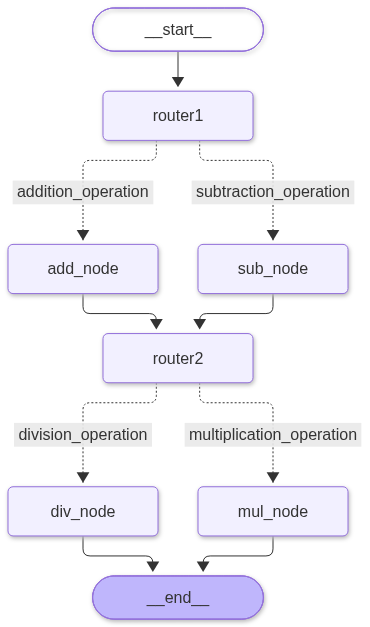

In [30]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [31]:
result = AgentState(number1=10, number2=5, number3=2, operation1="add", operation2="mul")
print(app.invoke(result))

{'number1': 10, 'number2': 5, 'number3': 2, 'operation1': 'add', 'operation2': 'mul', 'final': 30}
